# Daily Heart Rate Recovery Timeline

Visualises the **intraday HR curve** for each of the past 14 days and overlays morning workout windows.
After the workout the chart shows how long your heart rate takes to settle back to your personal baseline.

**What it answers:**
- How quickly does HR recover after a run vs gym vs run+gym?
- Which days showed the longest/shortest recovery?
- How does the rest-of-day HR compare across workout types?

**Data sources (Garmin Connect):**
- `get_heart_rates(date)` → 15-min intraday HR values
- `get_activities_by_date()` → workout start time, type, duration

In [34]:
import sys
import datetime as _dt
from pathlib import Path
from datetime import datetime, timedelta, date, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(repo_root / "src"))

from garmin_connect_downloader import authenticate, _require_client

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)
print(f"Repo root: {repo_root}")


Repo root: c:\Users\A717631\repo\theEagle


## Authentication
Uses `GARMIN_EMAIL` and `GARMIN_PASSWORD` environment variables (or will prompt).

In [35]:
authenticate(email=None, password=None)
print("Authenticated with Garmin Connect")

mobile+cffi returned 429: Mobile login returned 429 — IP rate limited by Garmin
mobile+requests returned 429: Mobile login returned 429 — IP rate limited by Garmin


Authenticated with Garmin Connect


## Configuration
Adjust the date window below. Default: last 14 days. Increase `DAYS_BACK` when you need a longer analysis window.

In [36]:
# ─── CONFIGURATION ────────────────────────────────────────────────────────────
DAYS_BACK: int = 28         # default: last 14 days; increase if needed
MORNING_END_HOUR: int = 12   # activities starting before this hour count as "morning"

# Activity type keys as Garmin reports them — extend if needed
RUNNING_KEYS = {"running", "trail_running", "treadmill_running", "indoor_running", "virtual_run"}
GYM_KEYS     = {"strength_training", "gym_and_fitness_equipment", "fitness_equipment",
                "indoor_cycling", "elliptical", "stair_climbing", "yoga", "pilates",
                "bouldering", "swimming", "lap_swimming"}

# HR baseline: HR is considered "settled" when it drops to within this many bpm
# above resting HR for a sustained window
SETTLE_MARGIN_BPM: int = 10      # within N bpm of resting HR = settled
SETTLE_WINDOW_MIN: int = 15      # must stay settled for at least this many minutes
# ──────────────────────────────────────────────────────────────────────────────

end_date   = date.today()
start_date = end_date - timedelta(days=DAYS_BACK - 1)

date_range = [start_date + timedelta(days=i) for i in range(DAYS_BACK)]
print(f"Analysing {len(date_range)} days: {start_date} → {end_date}")

Analysing 28 days: 2026-07-21 → 2026-08-17


## Fetch Data from Garmin Connect
One call per day for HR, plus one call for activities across the whole window.

In [37]:
client = _require_client()

# ── 1. Intraday heart-rate data (one call per day) ────────────────────────────
hr_raw: dict[str, dict] = {}
for d in date_range:
    ds = d.strftime("%Y-%m-%d")
    try:
        hr_raw[ds] = client.get_heart_rates(ds)
        n = len((hr_raw[ds] or {}).get("heartRateValues", []))
        print(f"  {ds}: {n} HR samples")
    except Exception as exc:
        print(f"  {ds}: WARN – {exc}")
        hr_raw[ds] = {}

print(f"\nFetched HR data for {sum(1 for v in hr_raw.values() if v)} days")

  2026-07-21: 532 HR samples
  2026-07-22: 430 HR samples
  2026-07-23: 414 HR samples
  2026-07-24: 496 HR samples
  2026-07-25: 479 HR samples
  2026-07-26: 328 HR samples
  2026-07-27: 402 HR samples
  2026-07-28: 325 HR samples
  2026-07-29: 381 HR samples
  2026-07-30: 405 HR samples
  2026-07-31: 502 HR samples
  2026-08-01: 389 HR samples
  2026-08-02: 477 HR samples
  2026-08-03: 351 HR samples
  2026-08-04: 476 HR samples
  2026-08-05: 454 HR samples
  2026-08-06: 510 HR samples
  2026-08-07: 628 HR samples
  2026-08-08: 455 HR samples
  2026-08-09: 585 HR samples
  2026-08-10: 480 HR samples
  2026-08-11: 471 HR samples
  2026-08-12: 570 HR samples
  2026-08-13: 532 HR samples
  2026-08-14: 525 HR samples
  2026-08-15: 596 HR samples
  2026-08-16: 345 HR samples
  2026-08-17: 8 HR samples

Fetched HR data for 28 days


In [38]:
# ── 2. Activities for the window ──────────────────────────────────────────────
start_str = start_date.strftime("%Y-%m-%d")
end_str   = end_date.strftime("%Y-%m-%d")

try:
    activities_raw = client.get_activities_by_date(start_str, end_str)
except Exception:
    # Older library versions use a different signature
    activities_raw = client.get_activities(0, 100)

print(f"Retrieved {len(activities_raw)} activities")

Retrieved 25 activities


## Parse and Structure Data

In [39]:
def _local_tz_from_raw(raw: dict):
    """Derive a fixed UTC offset from Garmin's GMT vs Local timestamps."""
    gmt_s   = (raw or {}).get("startTimestampGMT", "")
    local_s = (raw or {}).get("startTimestampLocal", "")
    if gmt_s and local_s:
        try:
            gmt_dt   = pd.to_datetime(gmt_s.replace("T", " "))
            local_dt = pd.to_datetime(local_s.replace("T", " "))
            offset_min = int((local_dt - gmt_dt).total_seconds() / 60)
            return timezone(timedelta(minutes=offset_min))
        except Exception:
            pass
    return timezone.utc


def _parse_hr_values(raw: dict) -> pd.DataFrame:
    """Convert Garmin heartRateValues list → tidy DataFrame with correct local time."""
    values = (raw or {}).get("heartRateValues", [])
    if not values:
        return pd.DataFrame(columns=["time", "bpm"])

    local_tz = _local_tz_from_raw(raw)

    rows = []
    for entry in values:
        if isinstance(entry, (list, tuple)) and len(entry) == 2:
            epoch_ms, bpm = entry
        elif isinstance(entry, dict):
            epoch_ms = entry.get("timestamp") or entry.get("startGMT")
            bpm      = entry.get("value") or entry.get("heartRate")
        else:
            continue
        if bpm is not None and epoch_ms is not None:
            # Convert UTC epoch → device-local naive datetime
            utc_dt   = datetime.fromtimestamp(int(epoch_ms) / 1000, tz=timezone.utc)
            local_dt = utc_dt.astimezone(local_tz).replace(tzinfo=None)
            rows.append({"time": pd.Timestamp(local_dt), "bpm": int(bpm)})

    if not rows:
        return pd.DataFrame(columns=["time", "bpm"])

    df = pd.DataFrame(rows).drop_duplicates("time").sort_values("time").reset_index(drop=True)
    df["bpm"] = pd.to_numeric(df["bpm"], errors="coerce")
    return df


# Build per-day HR DataFrames
hr_days: dict[str, pd.DataFrame] = {}
resting_hr: dict[str, float]     = {}

for ds, raw in hr_raw.items():
    df = _parse_hr_values(raw)
    hr_days[ds] = df
    reported_resting = (raw or {}).get("restingHeartRate")
    if reported_resting:
        resting_hr[ds] = float(reported_resting)
    elif not df.empty:
        night = df[df["time"].dt.hour < 6]
        resting_hr[ds] = float(night["bpm"].quantile(0.10)) if not night.empty else float(df["bpm"].quantile(0.10))
    else:
        resting_hr[ds] = np.nan

sample_raw = next((v for v in hr_raw.values() if v), {})
detected_tz = _local_tz_from_raw(sample_raw)
print(f"Detected local timezone offset: {detected_tz}")
print("\nResting HR per day — first sample time:")
for ds, rhr in sorted(resting_hr.items()):
    t0 = hr_days[ds]["time"].iloc[0] if not hr_days[ds].empty else "n/a"
    print(f"  {ds}: resting={rhr:.0f}  first_sample={t0}")


Detected local timezone offset: UTC+05:30

Resting HR per day — first sample time:
  2026-07-21: resting=47  first_sample=2026-07-21 00:00:00
  2026-07-22: resting=54  first_sample=2026-07-22 00:00:00
  2026-07-23: resting=51  first_sample=2026-07-23 00:00:00
  2026-07-24: resting=56  first_sample=2026-07-24 00:00:00
  2026-07-25: resting=55  first_sample=2026-07-25 00:00:00
  2026-07-26: resting=56  first_sample=2026-07-26 05:50:00
  2026-07-27: resting=56  first_sample=2026-07-27 00:00:00
  2026-07-28: resting=56  first_sample=2026-07-28 00:00:00
  2026-07-29: resting=55  first_sample=2026-07-29 00:00:00
  2026-07-30: resting=55  first_sample=2026-07-30 00:00:00
  2026-07-31: resting=54  first_sample=2026-07-31 00:00:00
  2026-08-01: resting=57  first_sample=2026-08-01 04:22:00
  2026-08-02: resting=56  first_sample=2026-08-02 00:00:00
  2026-08-03: resting=52  first_sample=2026-08-03 00:00:00
  2026-08-04: resting=52  first_sample=2026-08-04 00:00:00
  2026-08-05: resting=55  first_

In [40]:
def _classify_activity(type_key: str) -> str:
    tk = (type_key or "").lower()
    if tk in RUNNING_KEYS:
        return "running"
    if tk in GYM_KEYS:
        return "gym"
    return "other"


def _parse_activities(activities_raw: list) -> pd.DataFrame:
    rows = []
    for act in activities_raw:
        # Garmin can nest the summary differently depending on the API version
        summary = act.get("summaryDTO") or act
        type_key = (
            (act.get("activityType") or {}).get("typeKey")
            or summary.get("activityType")
            or ""
        )
        start_local = (
            summary.get("startTimeLocal")
            or act.get("startTimeLocal")
            or ""
        )
        duration_s = float(summary.get("duration") or act.get("duration") or 0)
        name = act.get("activityName") or summary.get("activityName") or type_key

        if not start_local:
            continue

        try:
            start_dt = pd.to_datetime(start_local)
        except Exception:
            continue

        rows.append({
            "date":       start_dt.strftime("%Y-%m-%d"),
            "start":      start_dt,
            "end":        start_dt + timedelta(seconds=duration_s),
            "duration_min": duration_s / 60,
            "type_key":   type_key,
            "category":   _classify_activity(type_key),
            "name":       name,
        })

    return pd.DataFrame(rows) if rows else pd.DataFrame(
        columns=["date","start","end","duration_min","type_key","category","name"])


acts_df = _parse_activities(activities_raw)

# Keep only morning activities within our date range
if not acts_df.empty:
    acts_df = acts_df[
        acts_df["date"].isin([d.strftime("%Y-%m-%d") for d in date_range])
        & (acts_df["start"].dt.hour < MORNING_END_HOUR)
    ].reset_index(drop=True)

print(f"Morning activities found: {len(acts_df)}")
if not acts_df.empty:
    display(acts_df[["date","start","duration_min","category","name"]].head(20))

Morning activities found: 20


,date,start,duration_min,category,name
0,2026-08-15,2026-08-15 05:35:29,65.973885,running,Chennai - Base
1,2026-08-14,2026-08-14 06:01:05,87.353084,gym,Day 6 - Legs
2,2026-08-13,2026-08-13 06:40:16,51.499532,gym,Day 4 - Core + Cardio
3,2026-08-13,2026-08-13 05:28:33,63.281250,running,Chennai - Base
4,2026-08-12,2026-08-12 05:50:37,120.406234,gym,Day 3 - Shoulder
5,2026-08-11,2026-08-11 06:14:29,101.128752,gym,Day 2 - Back & Biceps
6,2026-08-11,2026-08-11 05:36:51,26.026967,running,Chennai - Recovery
7,2026-08-10,2026-08-10 06:18:02,104.382048,gym,Strength
8,2026-08-10,2026-08-10 05:31:15,41.580632,running,Chennai - Sprint
9,2026-08-08,2026-08-08 05:31:26,75.749398,running,Chennai - Long Run


## Recovery Analysis
For each day with a morning workout, compute when HR finally settled back to baseline.

In [41]:
def compute_recovery_time(
    hr_df: pd.DataFrame,
    workout_end: pd.Timestamp,
    resting: float,
    margin: int = SETTLE_MARGIN_BPM,
    window_min: int = SETTLE_WINDOW_MIN,
) -> tuple:
    """Return (settle_time, recovery_minutes) after workout_end."""
    if hr_df.empty or np.isnan(resting):
        return None, None

    # Normalize both sides to tz-naive for comparison
    hr_times_naive = (
        hr_df["time"].dt.tz_localize(None)
        if hr_df["time"].dt.tz is not None
        else hr_df["time"]
    )
    we_naive = (
        workout_end.tz_localize(None)
        if getattr(workout_end, "tzinfo", None) is not None
        else pd.Timestamp(workout_end)
    )

    post_mask = hr_times_naive >= we_naive
    post_bpm = hr_df["bpm"][post_mask].reset_index(drop=True)
    post_times_naive = hr_times_naive[post_mask].reset_index(drop=True)
    post_times_orig = hr_df["time"][post_mask].reset_index(drop=True)

    if post_bpm.empty:
        return None, None

    threshold = resting + margin
    below = post_bpm <= threshold

    window_rows = max(1, window_min)
    for i in range(len(post_bpm) - window_rows + 1):
        if below.iloc[i : i + window_rows].all():
            settle_time = post_times_orig.iloc[i]   # tz-aware for plotting
            recovery_min = (post_times_naive.iloc[i] - we_naive).total_seconds() / 60
            return settle_time, recovery_min

    return None, None


recovery_results = []

for ds in [d.strftime("%Y-%m-%d") for d in date_range]:
    hr_df   = hr_days.get(ds, pd.DataFrame())
    resting = resting_hr.get(ds, np.nan)
    day_acts = acts_df[acts_df["date"] == ds] if not acts_df.empty else pd.DataFrame()

    if day_acts.empty:
        recovery_results.append({"date": ds, "workout_type": "rest",
                                  "workout_end": None, "settle_time": None,
                                  "recovery_min": None, "resting_hr": resting})
        continue

    cats = set(day_acts["category"].tolist())
    if "running" in cats and "gym" in cats:
        workout_type = "run+gym"
    elif "running" in cats:
        workout_type = "running"
    elif "gym" in cats:
        workout_type = "gym"
    else:
        workout_type = "other"

    workout_end = day_acts["end"].max()
    settle_time, recovery_min = compute_recovery_time(hr_df, workout_end, resting)

    recovery_results.append({
        "date":         ds,
        "workout_type": workout_type,
        "workout_end":  workout_end,
        "settle_time":  settle_time,
        "recovery_min": recovery_min,
        "resting_hr":   resting,
    })

recovery_df = pd.DataFrame(recovery_results)
recovery_df["date"] = pd.to_datetime(recovery_df["date"])
print(recovery_df[["date","workout_type","recovery_min","resting_hr"]].to_string(index=False))


      date workout_type  recovery_min  resting_hr
2026-07-21      running           NaN        47.0
2026-07-22         rest           NaN        54.0
2026-07-23      running           NaN        51.0
2026-07-24         rest           NaN        56.0
2026-07-25      running           NaN        55.0
2026-07-26         rest           NaN        56.0
2026-07-27         rest           NaN        56.0
2026-07-28         rest           NaN        56.0
2026-07-29         rest           NaN        55.0
2026-07-30         rest           NaN        55.0
2026-07-31         rest           NaN        54.0
2026-08-01         rest           NaN        57.0
2026-08-02         rest           NaN        56.0
2026-08-03          gym    812.869401        52.0
2026-08-04      run+gym    894.389803        52.0
2026-08-05         rest           NaN        55.0
2026-08-06      run+gym    867.682503        51.0
2026-08-07          gym    886.488184        54.0
2026-08-08      running           NaN        56.0


## Per-Day Timeline Charts
One row per day. Green shading = running, orange = gym, purple = run+gym.  
The dashed red line marks resting HR + settle margin. The star marks the settle point.

Days with HR data: 28


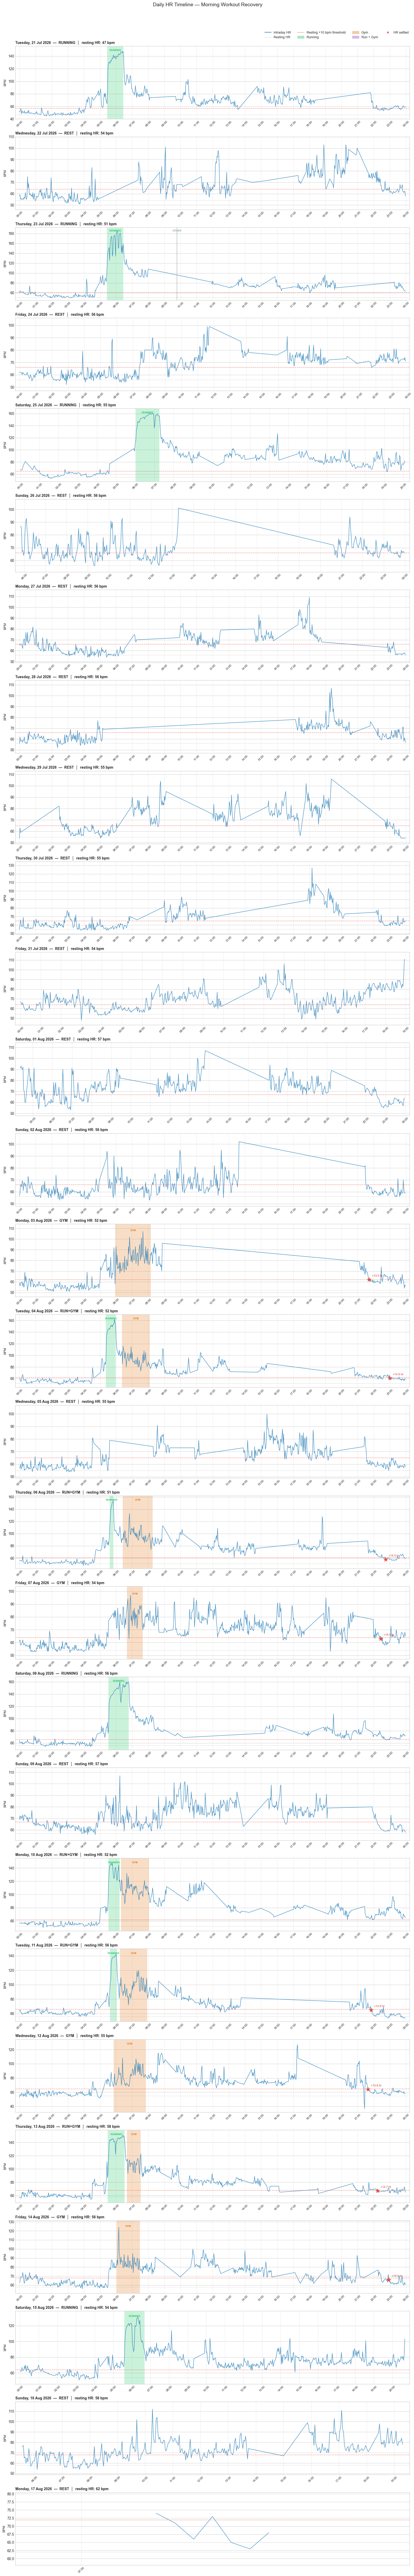

Chart saved to reports/daily_hr_recovery_timeline.png


In [42]:
WORKOUT_COLORS = {
    "running": "#2ecc71",
    "gym":     "#e67e22",
    "run+gym": "#9b59b6",
    "other":   "#95a5a6",
}

# ── Normalize everything to tz-naive for matplotlib compatibility ─────────────
hr_plot = {}
for ds, df in hr_days.items():
    if df.empty:
        hr_plot[ds] = df
    else:
        dfp = df.copy()
        if dfp["time"].dt.tz is not None:
            dfp["time"] = dfp["time"].dt.tz_localize(None)
        hr_plot[ds] = dfp

acts_plot = acts_df.copy() if not acts_df.empty else acts_df
if not acts_plot.empty:
    for col in ("start", "end"):
        if acts_plot[col].dt.tz is not None:
            acts_plot[col] = acts_plot[col].dt.tz_localize(None)

rec_plot = recovery_df.copy()
if "settle_time" in rec_plot.columns:
    def _strip_tz(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return None
        ts = pd.Timestamp(v)
        return ts.tz_localize(None) if ts.tzinfo is not None else ts
    rec_plot["settle_time"] = rec_plot["settle_time"].apply(_strip_tz)
# ─────────────────────────────────────────────────────────────────────────────

days_with_data = [ds for ds in [d.strftime("%Y-%m-%d") for d in date_range]
                  if not hr_plot.get(ds, pd.DataFrame()).empty]
print(f"Days with HR data: {len(days_with_data)}")

n_rows = len(days_with_data)
if n_rows == 0:
    print("No intraday HR data available for the selected range.")
else:
    fig, axes = plt.subplots(
        nrows=n_rows, ncols=1,
        figsize=(16, 3.5 * n_rows),
        sharex=False,
    )
    if n_rows == 1:
        axes = [axes]

    for ax, ds in zip(axes, days_with_data):
        hr_df    = hr_plot[ds]
        resting  = resting_hr.get(ds, np.nan)
        day_acts = acts_plot[acts_plot["date"] == ds] if not acts_plot.empty else pd.DataFrame()
        rec_row  = rec_plot[rec_plot["date"] == pd.Timestamp(ds)]

        ax.plot(hr_df["time"], hr_df["bpm"], color="#2980b9", lw=1.2, alpha=0.85)

        y_top = float(hr_df["bpm"].max()) * 1.02
        y_bot = max(0, float(hr_df["bpm"].min()) - 5)

        if not np.isnan(resting):
            ax.axhline(resting, color="gray", lw=0.8, ls=":", alpha=0.7)
            ax.axhline(resting + SETTLE_MARGIN_BPM, color="#e74c3c", lw=1.0, ls="--", alpha=0.7)

        if not day_acts.empty:
            for _, act in day_acts.iterrows():
                color = WORKOUT_COLORS.get(act["category"], WORKOUT_COLORS["other"])
                ax.axvspan(act["start"], act["end"], alpha=0.25, color=color, lw=0)
                mid = act["start"] + (act["end"] - act["start"]) / 2
                ax.text(mid, y_top, act["category"].upper(),
                        ha="center", va="top", fontsize=7, color=color, fontweight="bold")

        if not rec_row.empty:
            st = rec_row.iloc[0]["settle_time"]
            rec_min = rec_row.iloc[0]["recovery_min"]
            if st is not None and pd.notna(st):
                diff = (hr_df["time"] - st).abs()
                idx_closest = diff.idxmin()
                bpm_at_settle = hr_df.loc[idx_closest, "bpm"]
                ax.scatter([hr_df.loc[idx_closest, "time"]], [bpm_at_settle],
                           marker="*", s=140, color="#e74c3c", zorder=5)
                ax.annotate(f"+{rec_min/60:.1f} hr",
                            xy=(hr_df.loc[idx_closest, "time"], bpm_at_settle),
                            xytext=(8, 8), textcoords="offset points",
                            fontsize=8, color="#c0392b")

        wtype = rec_row.iloc[0]["workout_type"] if not rec_row.empty else "rest"
        title = f"{pd.Timestamp(ds).strftime('%A, %d %b %Y')}  —  {wtype.upper()}"
        if not np.isnan(resting):
            title += f"  │  resting HR: {resting:.0f} bpm"
        ax.set_title(title, loc="left", fontsize=10, fontweight="bold")
        ax.set_ylabel("BPM", fontsize=9)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
        ax.tick_params(axis="x", labelrotation=45, labelsize=8)
        ax.set_xlim(hr_df["time"].min() - timedelta(minutes=15),
                    hr_df["time"].max() + timedelta(minutes=15))
        ax.set_ylim(y_bot, y_top + 5)
        ax.grid(axis="x", alpha=0.4)

    legend_elements = [
        Line2D([0],[0], color="#2980b9", lw=1.5, label="Intraday HR"),
        Line2D([0],[0], color="gray",    lw=0.8, ls=":",  label="Resting HR"),
        Line2D([0],[0], color="#e74c3c", lw=1.0, ls="--", label=f"Resting +{SETTLE_MARGIN_BPM} bpm threshold"),
        mpatches.Patch(color=WORKOUT_COLORS["running"], alpha=0.4, label="Running"),
        mpatches.Patch(color=WORKOUT_COLORS["gym"],     alpha=0.4, label="Gym"),
        mpatches.Patch(color=WORKOUT_COLORS["run+gym"], alpha=0.4, label="Run + Gym"),
        Line2D([0],[0], marker="*", color="w", markerfacecolor="#e74c3c", markersize=10, label="HR settled"),
    ]
    fig.legend(handles=legend_elements, loc="upper right", ncol=4, fontsize=9,
               bbox_to_anchor=(0.99, 1.0))
    fig.suptitle("Daily HR Timeline — Morning Workout Recovery", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(repo_root / "reports" / "daily_hr_recovery_timeline.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print("Chart saved to reports/daily_hr_recovery_timeline.png")


## Recovery Summary — Time to Settle by Workout Type

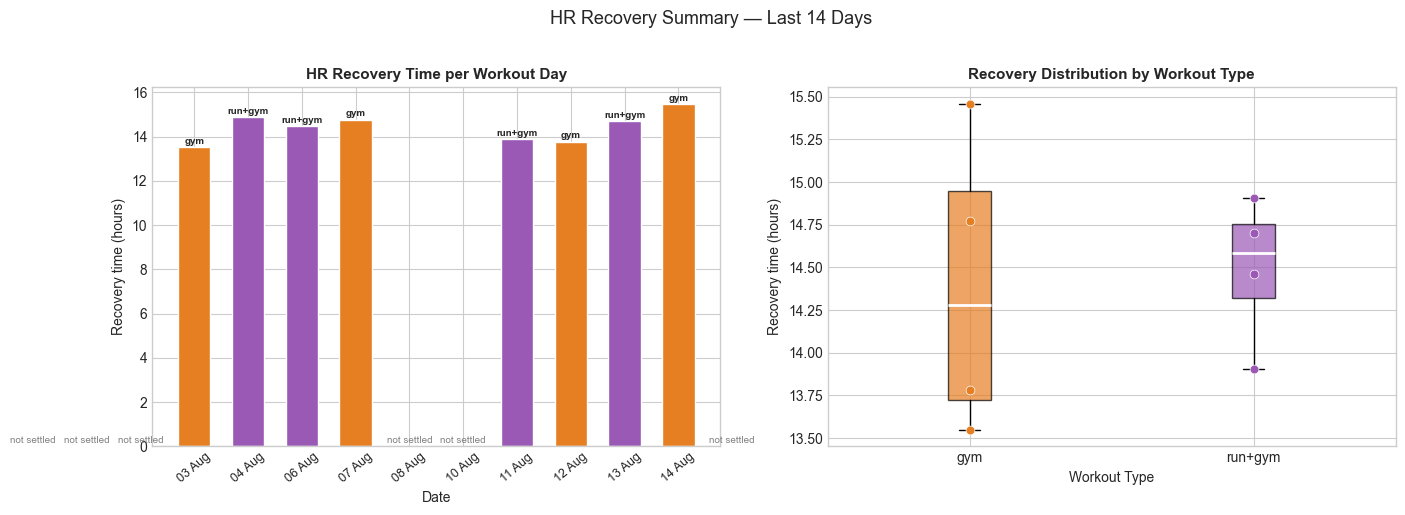

Summary chart saved to reports/daily_hr_recovery_summary.png


In [43]:
workout_days = recovery_df[recovery_df["workout_type"] != "rest"].copy()

if workout_days.empty:
    print("No workout days found in the selected range.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ── Left: recovery time per day (bar chart) ───────────────────────────────
    ax = axes[0]
    bar_colors = [WORKOUT_COLORS.get(wt, "#95a5a6") for wt in workout_days["workout_type"]]
    recovery_hr = workout_days["recovery_min"] / 60
    bars = ax.bar(
        workout_days["date"].dt.strftime("%d %b"),
        recovery_hr,
        color=bar_colors,
        edgecolor="white",
        width=0.6,
    )
    ax.set_xlabel("Date", fontsize=10)
    ax.set_ylabel("Recovery time (hours)", fontsize=10)
    ax.set_title("HR Recovery Time per Workout Day", fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", labelrotation=40, labelsize=9)

    for bar, wtype in zip(bars, workout_days["workout_type"]):
        h = bar.get_height()
        if pd.notna(h) and h > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.05,
                    wtype, ha="center", va="bottom", fontsize=7, fontweight="bold")
        elif pd.isna(h) or h == 0:
            ax.text(bar.get_x() + bar.get_width() / 2, 0.05,
                    "not settled", ha="center", va="bottom", fontsize=7, color="gray")

    # ── Right: box plot — recovery time by workout type ───────────────────────
    ax2 = axes[1]
    grouped = {
        wt: (workout_days[workout_days["workout_type"] == wt]["recovery_min"] / 60).dropna().tolist()
        for wt in workout_days["workout_type"].unique()
    }
    valid = {k: v for k, v in grouped.items() if len(v) >= 1}

    if valid:
        bp = ax2.boxplot(
            list(valid.values()),
            tick_labels=list(valid.keys()),
            patch_artist=True,
            medianprops=dict(color="white", lw=2),
        )
        for patch, wt in zip(bp["boxes"], valid.keys()):
            patch.set_facecolor(WORKOUT_COLORS.get(wt, "#95a5a6"))
            patch.set_alpha(0.7)

        for i, (wt, vals) in enumerate(valid.items(), start=1):
            ax2.scatter([i] * len(vals), vals, color=WORKOUT_COLORS.get(wt, "gray"),
                        zorder=5, s=40, edgecolors="white", lw=0.5)

    ax2.set_xlabel("Workout Type", fontsize=10)
    ax2.set_ylabel("Recovery time (hours)", fontsize=10)
    ax2.set_title("Recovery Distribution by Workout Type", fontsize=11, fontweight="bold")

    plt.suptitle("HR Recovery Summary — Last 14 Days", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(repo_root / "reports" / "daily_hr_recovery_summary.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print("Summary chart saved to reports/daily_hr_recovery_summary.png")


## Recovery Stats Table

In [44]:
if not workout_days.empty:
    stats = (
        workout_days.assign(recovery_hr=workout_days["recovery_min"] / 60)
        .groupby("workout_type")["recovery_hr"]
        .agg(
            days="count",
            settled=lambda x: x.notna().sum(),
            avg_recovery_hr="mean",
            min_recovery_hr="min",
            max_recovery_hr="max",
        )
        .round(2)
    )
    print("\nRecovery statistics by workout type:")
    display(stats)

    print("\nPer-day detail:")
    detail = recovery_df.copy()
    detail["recovery_hr"] = detail["recovery_min"] / 60
    display(
        detail[[
            "date", "workout_type", "resting_hr", "workout_end", "settle_time", "recovery_hr"
        ]].sort_values("date").reset_index(drop=True)
    )



Recovery statistics by workout type:


,days,settled,avg_recovery_hr,min_recovery_hr,max_recovery_hr
workout_type,,,,,
gym,4,4,14.39,13.55,15.46
run+gym,4,4,14.49,13.91,14.91
running,0,0,NaN,NaN,NaN



Per-day detail:


,date,workout_type,resting_hr,workout_end,settle_time,recovery_hr
0,2026-07-21,running,47.0,2026-07-21 06:27:09.888916,NaT,NaN
1,2026-07-22,rest,54.0,NaT,NaT,NaN
2,2026-07-23,running,51.0,2026-07-23 09:49:18.000000,NaT,NaN
3,2026-07-24,rest,56.0,NaT,NaT,NaN
4,2026-07-25,running,55.0,2026-07-25 07:15:48.824219,NaT,NaN
5,2026-07-26,rest,56.0,NaT,NaT,NaN
6,2026-07-27,rest,56.0,NaT,NaT,NaN
7,2026-07-28,rest,56.0,NaT,NaT,NaN
8,2026-07-29,rest,55.0,NaT,NaT,NaN
9,2026-07-30,rest,55.0,NaT,NaT,NaN
